# Insurance Claim Fraud Detection
## Exploratory Data Analysis (EDA)

### Objective
Explore insurance claim data to understand claim characteristics,
financial exposure, and patterns associated with the existing fraud labels.

### Business Questions
1. What is the overall claim volume?
2. What proportion of claims are labelled fraudulent?
3. How are claim amounts distributed?
4. How do claim amounts differ by fraud label?
5. Which claim characteristics are associated with different fraud rates?

### Tools
- Python
- Pandas
- Matplotlib
- Seaborn

### Important Note
This analysis identifies patterns and associations in the available data.
It does not independently establish that a claim is fraudulent.

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load the dataset
df = pd.read_csv("../data/raw/insurance_claim_fraud_dataset.csv")

# Convert date columns
date_columns = [
    "claim_date",
    "incident_date",
    "policy_start_date"
]

for col in date_columns:
    df[col] = pd.to_datetime(df[col], errors="coerce")

print("Dataset loaded successfully")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

Dataset loaded successfully
Rows: 100000
Columns: 62


In [3]:
# Overall claims overview

total_claims = len(df)

fraudulent_claims = (df["fraudulent"] == "Yes").sum()
non_fraudulent_claims = (df["fraudulent"] == "No").sum()

fraud_rate = fraudulent_claims / total_claims * 100

print("OVERALL CLAIMS OVERVIEW")
print("-" * 35)
print(f"Total claims: {total_claims:,}")
print(f"Fraud-labelled claims: {fraudulent_claims:,}")
print(f"Non-fraud-labelled claims: {non_fraudulent_claims:,}")
print(f"Fraud-label rate: {fraud_rate:.2f}%")

OVERALL CLAIMS OVERVIEW
-----------------------------------
Total claims: 100,000
Fraud-labelled claims: 20,042
Non-fraud-labelled claims: 79,958
Fraud-label rate: 20.04%


### 1. Claim Amount Analysis

Analyze the distribution of claim amounts and compare financial patterns between claims labelled fraudulent and non-fraudulent.

In [4]:
# Claim amount summary statistics

print("CLAIM AMOUNT SUMMARY")
print("-" * 40)

print(
    df["claim_amount"].describe().round(2)
)

print("\nCLAIM AMOUNT BY FRAUD LABEL")
print("-" * 40)

claim_summary = (
    df.groupby("fraudulent")["claim_amount"]
    .agg(["count", "mean", "median", "min", "max"])
    .round(2)
)

print(claim_summary)

CLAIM AMOUNT SUMMARY
----------------------------------------
count    100000.00
mean       7066.21
std        9085.48
min          70.70
25%        1057.01
50%        3585.38
75%        9291.07
max       71055.16
Name: claim_amount, dtype: float64

CLAIM AMOUNT BY FRAUD LABEL
----------------------------------------
            count    mean   median    min       max
fraudulent                                         
No          79958  6632.7  3424.16  70.70  71055.16
Yes         20042  8795.7  4428.20  73.79  64484.38


### Key Findings

- The average claim amount was 7,066.21, while the median was 3,585.38.
- The average claim amount for fraud-labelled claims was higher than for non-fraud-labelled claims.
- Fraud-labelled claims had an average claim amount of 8,795.70, compared with 6,632.70 for non-fraud-labelled claims.
- The difference suggests an association between claim amount and the existing fraud labels. Claim amount alone cannot establish fraud.

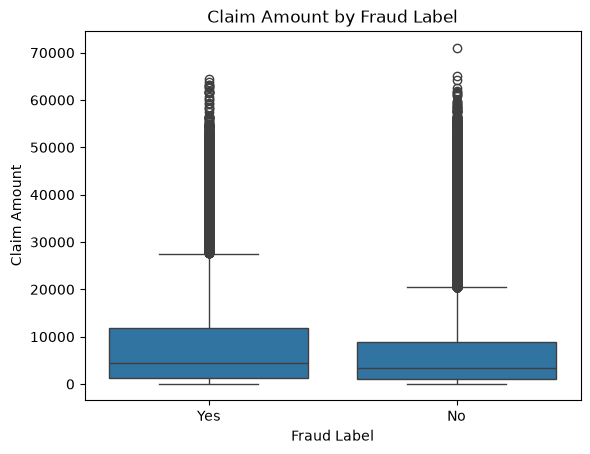

In [5]:
# visualize claim amt

sns.boxplot(data=df, x="fraudulent", y="claim_amount")
plt.title("Claim Amount by Fraud Label")
plt.xlabel("Fraud Label")
plt.ylabel("Claim Amount")
plt.show()

The box plot shows that fraud-labelled claims have a higher median claim amount than non-fraud-labelled claims. Both groups contain numerous high-value outliers, and their distributions overlap considerably. Therefore, claim amount may be useful for identifying claims for further review, but it cannot independently establish fraud.

### 2. Claim Amount by Incident Type

Comparing claim amounts across incident types to identify differences in financial exposure.

In [6]:
incident_amounts = df.groupby("incident_type")["claim_amount"].mean().sort_values(ascending=False)

print(incident_amounts.round(2))

incident_type
Parked Vehicle              7117.81
Animal Impact               7117.63
Vandalism                   7103.69
Theft                       7064.79
Multi-Vehicle Collision     7014.47
Single Vehicle Collision    6978.06
Name: claim_amount, dtype: float64


### Key Findings

- Parked Vehicle claims had the highest average claim amount at 7,117.81.
- Single Vehicle Collision claims had the lowest average at 6,978.06.
- The difference between the highest and lowest averages was 139.75.
- Average claim amounts were relatively similar across incident types.

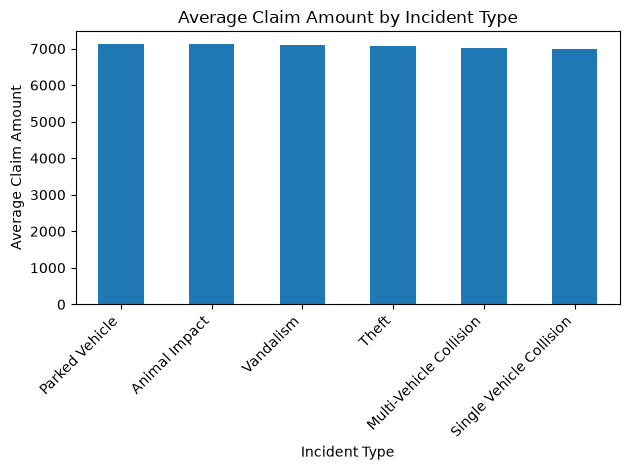

In [7]:
incident_amounts.plot(kind="bar")

plt.title("Average Claim Amount by Incident Type")
plt.xlabel("Incident Type")
plt.ylabel("Average Claim Amount")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

### 3. Fraud Rate by Incident Type

Compare fraud-label rates across incident types to identify categories with different proportions of fraud-labelled claims.

incident_type
Single Vehicle Collision    20.46
Parked Vehicle              20.21
Vandalism                   20.08
Animal Impact               19.91
Theft                       19.88
Multi-Vehicle Collision     19.71
Name: fraudulent, dtype: float64


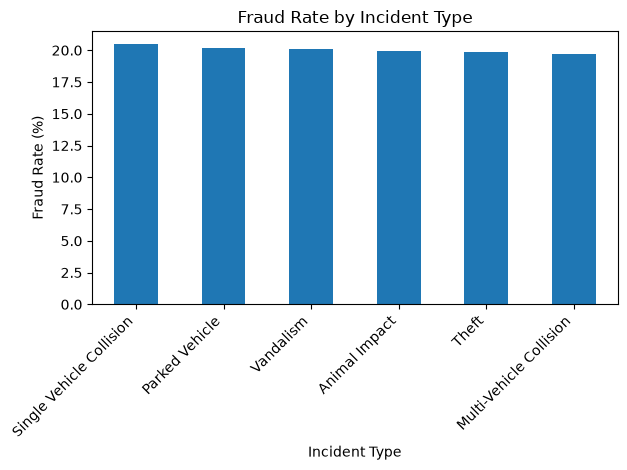

In [8]:
fraud_by_incident = df.groupby("incident_type")["fraudulent"].apply(
    lambda x: (x == "Yes").mean() * 100
).sort_values(ascending=False)

print(fraud_by_incident.round(2))

fraud_by_incident.plot(kind="bar")

plt.title("Fraud Rate by Incident Type")
plt.xlabel("Incident Type")
plt.ylabel("Fraud Rate (%)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

### Key Findings

- Single Vehicle Collision had the highest fraud-label rate at 20.46%.
- Multi-Vehicle Collision had the lowest rate at 19.71%.
- The difference between the highest and lowest rates was 0.75 percentage points.
- Fraud-label rates were relatively similar across all incident types.
- Incident type alone may not be sufficient to distinguish fraud-labelled claims.

### 4. Fraud Rate by Policy Type

Compare fraud-label rates across policy types to identify differences between insurance categories.

Fraud Rate by Policy Type
policy_type
Uninsured Motorist            20.17
Personal Injury Protection    20.12
Collision                     20.12
Comprehensive                 19.96
Liability Only                19.86
Name: fraudulent, dtype: float64


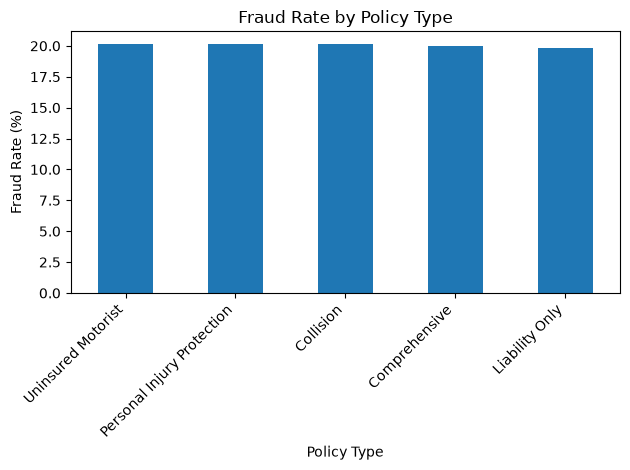

In [9]:
fraud_by_policy = df.groupby("policy_type")["fraudulent"].apply(
    lambda x: (x == "Yes").mean() * 100
).sort_values(ascending=False)

print("Fraud Rate by Policy Type")
print(fraud_by_policy.round(2))

fraud_by_policy.plot(kind="bar")

plt.title("Fraud Rate by Policy Type")
plt.xlabel("Policy Type")
plt.ylabel("Fraud Rate (%)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

### Key Findings

- Uninsured Motorist policies had the highest fraud-label rate at 20.17%.
- Liability Only policies had the lowest rate at 19.86%.
- The difference between the highest and lowest rates was 0.31 percentage points.
- Fraud-label rates were similar across all five policy types.
- Policy type alone may not be sufficient to distinguish fraud-labelled claims.

### 5. Claims Exceeding Coverage

Analyze how frequently claim amounts exceed the corresponding coverage amount and compare the fraud-label rates between the two groups.

Fraud Rate by Coverage Status
Within Coverage     19.94
Exceeds Coverage    30.05
Name: fraudulent, dtype: float64


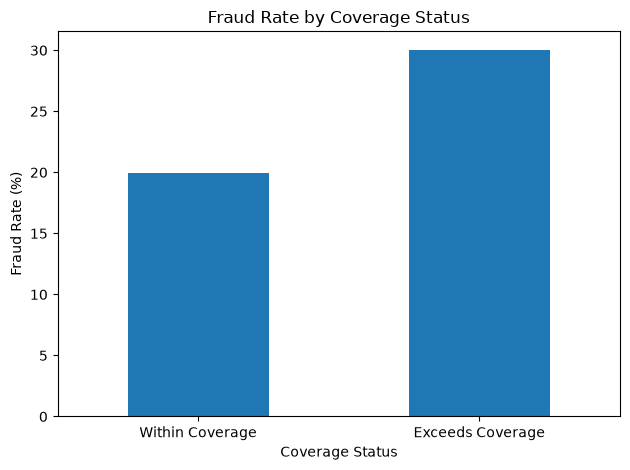

In [10]:
df["exceeds_coverage"] = df["claim_amount"] > df["coverage_amount"]

coverage_summary = df.groupby("exceeds_coverage")["fraudulent"].apply(
    lambda x: (x == "Yes").mean() * 100
)

coverage_summary.index = ["Within Coverage", "Exceeds Coverage"]

print("Fraud Rate by Coverage Status")
print(coverage_summary.round(2))

coverage_summary.plot(kind="bar")

plt.title("Fraud Rate by Coverage Status")
plt.xlabel("Coverage Status")
plt.ylabel("Fraud Rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### Key Findings

- Claims exceeding coverage had a fraud-label rate of 30.05%.
- Claims within coverage had a fraud-label rate of 19.94%.
- The difference between the two groups was 10.11 percentage points.
- Claims exceeding coverage may warrant additional review, subject to policy terms and conditions.
- Exceeding coverage alone does not establish fraud.

### 6. Previous Claims and Fraud Rate

Analyze whether the number of previous claims is associated with differences in fraud-label rates.

                 total_claims  fraud_rate
previous_claims                          
0                       44546       19.03
1                       36356       19.19
2                       14385       18.71
3                        3814       40.01
4                         739       40.46
5                         137       44.53
6                          20       35.00
7                           3      100.00


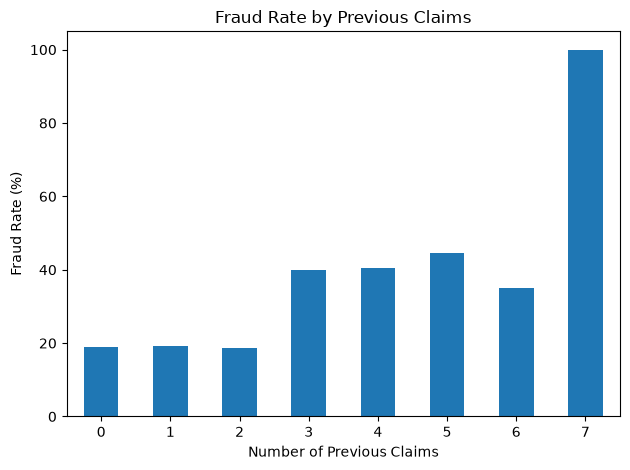

In [11]:
previous_claims = df.groupby("previous_claims")["fraudulent"].agg(
    total_claims="count",
    fraud_rate=lambda x: (x == "Yes").mean() * 100
)

print(previous_claims.round(2))

previous_claims["fraud_rate"].plot(kind="bar")

plt.title("Fraud Rate by Previous Claims")
plt.xlabel("Number of Previous Claims")
plt.ylabel("Fraud Rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### Key Findings

- Claims with 0–2 previous claims had fraud-label rates around 19%.
- Rates increased to approximately 40–45% for claims with 3–5 previous claims.
- The fraud-label rate for 7 previous claims was 100%, but this group contained only 3 records.
- Groups with fewer claims should be interpreted cautiously.
- Previous claim history may be useful when reviewing claims, but it cannot independently establish fraud.

### 7. Accident Severity and Fraud Rate

                   total_claims  fraud_rate
accident_severity                          
Major                     19992       24.56
Minor                     39979       17.67
Moderate                  30022       17.40
Total Loss                10007       28.42


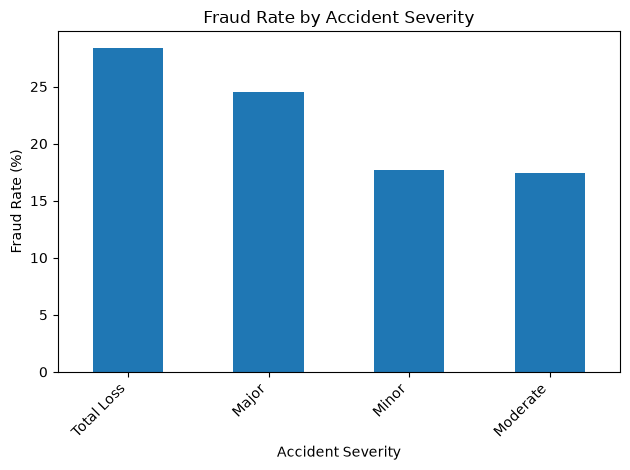

In [12]:
severity_rate = df.groupby("accident_severity")["fraudulent"].agg(
    total_claims="count",
    fraud_rate=lambda x: (x == "Yes").mean() * 100
)

print(severity_rate.round(2))

severity_rate["fraud_rate"].sort_values(ascending=False).plot(kind="bar")

plt.title("Fraud Rate by Accident Severity")
plt.xlabel("Accident Severity")
plt.ylabel("Fraud Rate (%)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

### Key Findings

- Total Loss claims had the highest fraud-label rate at 28.42%.
- Major accident claims had a fraud-label rate of 24.56%.
- Minor and Moderate accident claims had lower rates of 17.67% and 17.40%.
- The difference between Total Loss and Moderate was 11.02 percentage points.
- Accident severity may be useful for further claim review, but it cannot independently establish fraud.

### 8. Suspicious Documents and Fraud Rate

                      total_claims  fraud_rate
suspicious_documents                          
No                           91873       13.59
Yes                           8127       92.94


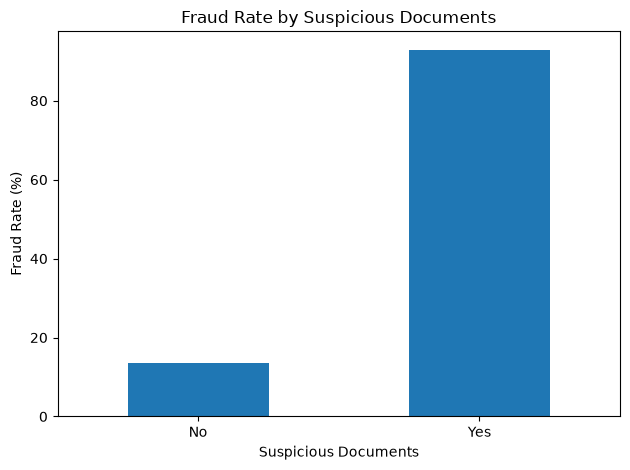

In [13]:
document_rate = df.groupby("suspicious_documents")["fraudulent"].agg(
    total_claims="count",
    fraud_rate=lambda x: (x == "Yes").mean() * 100
)

print(document_rate.round(2))

document_rate["fraud_rate"].plot(kind="bar")

plt.title("Fraud Rate by Suspicious Documents")
plt.xlabel("Suspicious Documents")
plt.ylabel("Fraud Rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### Key Findings

- Claims marked as having suspicious documents had a fraud-label rate of 92.94%.
- Claims without this indicator had a fraud-label rate of 13.59%.
- The difference between the groups was 79.35 percentage points.
- Suspicious documents showed a strong association with the existing fraud labels.
- The timing of this indicator should be verified before treating it as an early warning signal.

### 9. Identity Verification and Fraud Rate

Fraud Rate by Identity Verification
                   total_claims  fraud_rate
identity_verified                          
No                         8119       69.05
Yes                       91881       15.71


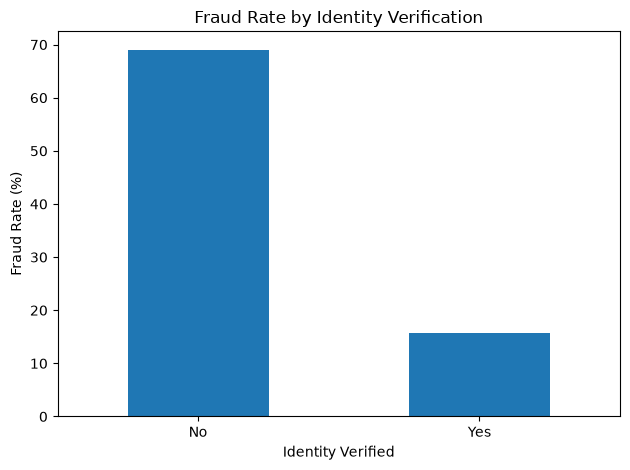

In [14]:
identity_rate = df.groupby("identity_verified")["fraudulent"].agg(
    total_claims="count",
    fraud_rate=lambda x: (x == "Yes").mean() * 100
)

print("Fraud Rate by Identity Verification")
print(identity_rate.round(2))

identity_rate["fraud_rate"].plot(kind="bar")

plt.title("Fraud Rate by Identity Verification")
plt.xlabel("Identity Verified")
plt.ylabel("Fraud Rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### Key Findings

- Claims without identity verification had a fraud-label rate of 69.05%.
- Claims with verified identities had a fraud-label rate of 15.71%.
- The difference between the groups was 53.34 percentage points.
- Identity verification status showed a strong association with the existing fraud labels.
- The timing of identity verification should be confirmed before treating it as an early warning indicator.

### 10. Inconsistent Statements and Fraud Rate

Fraud Rate by Inconsistent Statements
                         total_claims  fraud_rate
inconsistent_statements                          
No                              90954       17.04
Yes                              9046       50.24


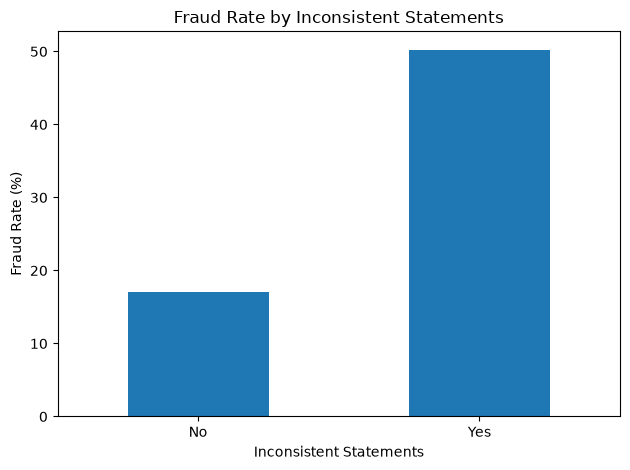

In [15]:
statement_rate = df.groupby("inconsistent_statements")["fraudulent"].agg(
    total_claims="count",
    fraud_rate=lambda x: (x == "Yes").mean() * 100
)

print("Fraud Rate by Inconsistent Statements")
print(statement_rate.round(2))

statement_rate["fraud_rate"].plot(kind="bar")

plt.title("Fraud Rate by Inconsistent Statements")
plt.xlabel("Inconsistent Statements")
plt.ylabel("Fraud Rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### Key Findings

- Claims with inconsistent statements had a fraud-label rate of 50.24%.
- Claims without inconsistent statements had a fraud-label rate of 17.04%.
- The difference between the groups was 33.20 percentage points.
- Inconsistent statements showed an association with the existing fraud labels.
- The timing of this indicator should be verified before treating it as an early warning signal.

### 11. Delayed Reporting and Fraud Rate

Fraud Rate by Delayed Reporting
                   total_claims  fraud_rate
delayed_reporting                          
No                        94874       19.04
Yes                        5126       38.51


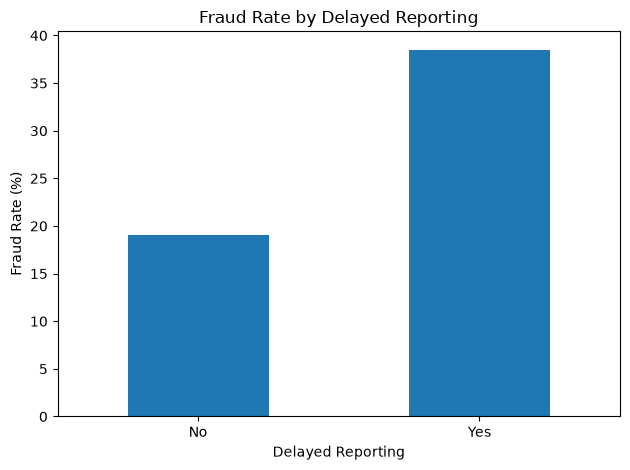

In [16]:
delayed_rate = df.groupby("delayed_reporting")["fraudulent"].agg(
    total_claims="count",
    fraud_rate=lambda x: (x == "Yes").mean() * 100
)

print("Fraud Rate by Delayed Reporting")
print(delayed_rate.round(2))

delayed_rate["fraud_rate"].plot(kind="bar")

plt.title("Fraud Rate by Delayed Reporting")
plt.xlabel("Delayed Reporting")
plt.ylabel("Fraud Rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### Key Findings

- Claims with delayed reporting had a fraud-label rate of 38.51%.
- Claims without delayed reporting had a fraud-label rate of 19.04%.
- The difference between the groups was 19.47 percentage points.
- Delayed reporting was associated with a higher fraud-label rate.
- Reporting delays alone do not establish fraud, and the timing of this indicator should be verified.

### 12. GPS Location Match and Fraud Rate

Fraud Rate by GPS Location Match
                    total_claims  fraud_rate
gps_location_match                          
No                         12032       48.71
Yes                        87968       16.12


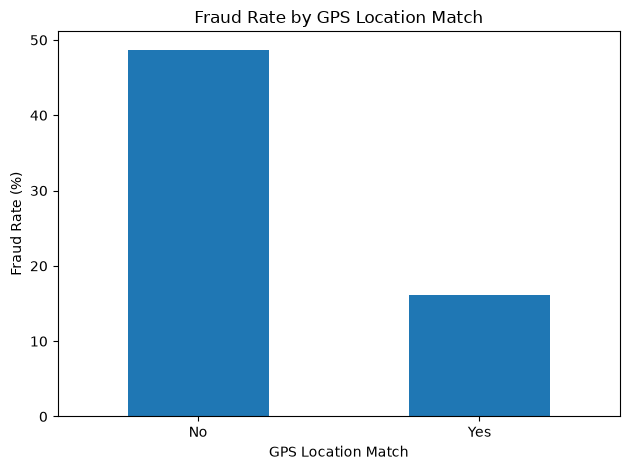

In [17]:
gps_rate = df.groupby("gps_location_match")["fraudulent"].agg(
    total_claims="count",
    fraud_rate=lambda x: (x == "Yes").mean() * 100
)

print("Fraud Rate by GPS Location Match")
print(gps_rate.round(2))

gps_rate["fraud_rate"].plot(kind="bar")

plt.title("Fraud Rate by GPS Location Match")
plt.xlabel("GPS Location Match")
plt.ylabel("Fraud Rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### Key Findings

- Claims without a GPS location match had a fraud-label rate of 48.71%.
- Claims with a GPS location match had a fraud-label rate of 16.12%.
- The difference between the groups was 32.59 percentage points.
- GPS location mismatch showed an association with the existing fraud labels.
- The timing and context of the location check should be verified before using it as an early warning indicator.

### 13. Repair Shop Verification and Fraud Rate

Fraud Rate by Repair Shop Verification
                      total_claims  fraud_rate
repair_shop_verified                          
No                           15144       28.96
Yes                          84856       18.45


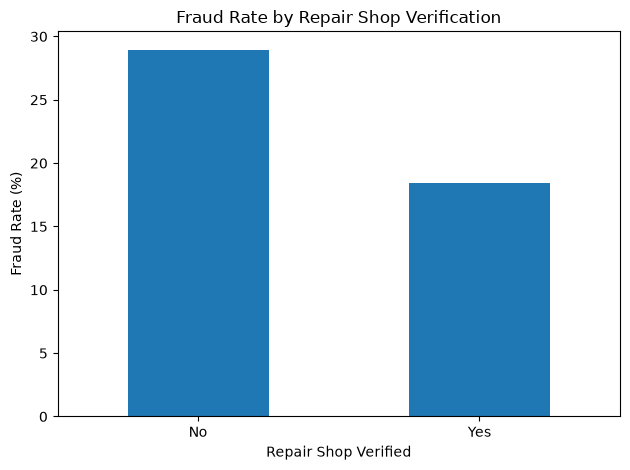

In [18]:
repair_rate = df.groupby("repair_shop_verified")["fraudulent"].agg(
    total_claims="count",
    fraud_rate=lambda x: (x == "Yes").mean() * 100
)

print("Fraud Rate by Repair Shop Verification")
print(repair_rate.round(2))

repair_rate["fraud_rate"].plot(kind="bar")

plt.title("Fraud Rate by Repair Shop Verification")
plt.xlabel("Repair Shop Verified")
plt.ylabel("Fraud Rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### Key Findings

- Claims without repair shop verification had a fraud-label rate of 28.96%.
- Claims with verified repair shops had a fraud-label rate of 18.45%.
- The difference between the groups was 10.51 percentage points.
- Lack of repair shop verification was associated with a higher fraud-label rate.
- Verification status alone does not establish fraud, and its timing should be verified.

### 14. Claim Submission Time and Fraud Rate

Fraud Rate by Claim Submission Time
                          total_claims  fraud_rate
claim_submitted_at_night                          
No                               85033       17.57
Yes                              14967       34.07


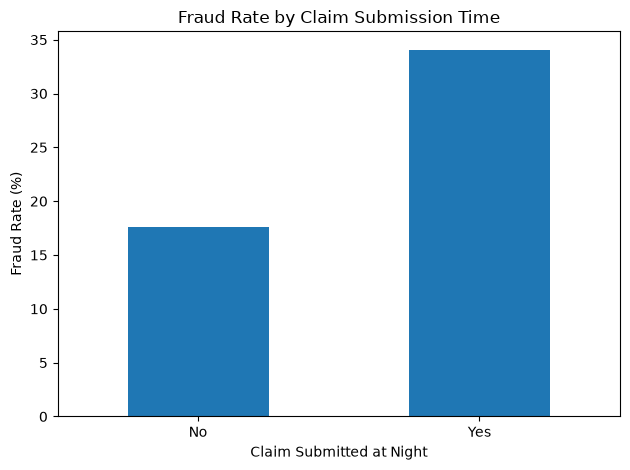

In [19]:
night_rate = df.groupby("claim_submitted_at_night")["fraudulent"].agg(
    total_claims="count",
    fraud_rate=lambda x: (x == "Yes").mean() * 100
)

print("Fraud Rate by Claim Submission Time")
print(night_rate.round(2))

night_rate["fraud_rate"].plot(kind="bar")

plt.title("Fraud Rate by Claim Submission Time")
plt.xlabel("Claim Submitted at Night")
plt.ylabel("Fraud Rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### Key Findings

- Claims submitted at night had a fraud-label rate of 34.07%.
- Claims not submitted at night had a fraud-label rate of 17.57%.
- The difference between the groups was 16.50 percentage points.
- Night-time submission was associated with a higher fraud-label rate.
- Submission time alone does not establish fraud.

## ---- Summary of Exploratory Data Analysis ----

This section summarizes the key patterns observed in claim amounts,
coverage limits, accident characteristics, previous claim history,
and investigation indicators.

The results describe associations with the existing fraud labels
and do not independently establish fraud.

In [20]:
eda_summary = pd.DataFrame({
    "Analysis": [
        "Overall fraud-label rate",
        "Average claim amount",
        "Claim amount by fraud label",
        "Claims exceeding coverage",
        "Previous claim history",
        "Accident severity",
        "Suspicious documents",
        "Identity verification",
        "Inconsistent statements",
        "Delayed reporting",
        "GPS location match",
        "Repair shop verification",
        "Night-time submission"
    ],
    "Key Finding": [
        "20.04% of claims were labelled fraudulent.",
        "The average claim amount was 7,066.21.",
        "Fraud-labelled claims averaged 8,795.70, compared with 6,632.70 for non-fraud-labelled claims.",
        "Fraud-label rate was 30.05% for claims exceeding coverage, compared with 19.94% for other claims.",
        "Fraud-label rates increased for groups with 3–5 previous claims; groups with few records require caution.",
        "Total Loss claims had the highest rate at 28.42%.",
        "Claims marked Yes had a rate of 92.94%.",
        "Claims marked No had a rate of 69.05%.",
        "Claims marked Yes had a rate of 50.24%.",
        "Claims marked Yes had a rate of 38.51%.",
        "Claims without a GPS match had a rate of 48.71%.",
        "Claims without repair shop verification had a rate of 28.96%.",
        "Claims submitted at night had a rate of 34.07%."
    ]
})

eda_summary

,Analysis,Key Finding
0,Overall fraud-label rate,20.04% of claims were labelled fraudulent.
1,Average claim amount,"The average claim amount was 7,066.21."
2,Claim amount by fraud label,"Fraud-labelled claims averaged 8,795.70, compa..."
3,Claims exceeding coverage,Fraud-label rate was 30.05% for claims exceedi...
4,Previous claim history,Fraud-label rates increased for groups with 3–...
5,Accident severity,Total Loss claims had the highest rate at 28.42%.
6,Suspicious documents,Claims marked Yes had a rate of 92.94%.
7,Identity verification,Claims marked No had a rate of 69.05%.
8,Inconsistent statements,Claims marked Yes had a rate of 50.24%.
9,Delayed reporting,Claims marked Yes had a rate of 38.51%.


## Major Business Findings

#### 1. Claim Amounts
Fraud-labelled claims had a higher average claim amount (8,795.70) than non-fraud-labelled claims (6,632.70).

#### 2. Claims Exceeding Coverage
Claims exceeding their coverage amount had a fraud-label rate of 30.05%, compared with 19.94% for other claims.

#### 3. Previous Claim History
Fraud-label rates were higher among claims with 3–5 previous claims. Results for groups with few records should be interpreted cautiously.

#### 4. Accident Severity
Total Loss claims had the highest fraud-label rate at 28.42%.

#### 5. Investigation Indicators
Suspicious documents, unverified identities, inconsistent statements, delayed reporting, GPS mismatches, and missing repair shop verification were associated with higher fraud-label rates.

#### 6. Submission Time
Claims submitted at night had a fraud-label rate of 34.07%, compared with 17.57% for other claims.

#### Important Limitation
These findings describe associations with existing fraud labels. They do not prove fraud. The timing and definitions of investigation-related indicators should be verified before treating them as early warning signals.

In [21]:
print(list(df.columns))

['claim_id', 'policy_id', 'customer_id', 'customer_name', 'claim_date', 'incident_date', 'claim_status', 'claim_amount', 'approved_amount', 'deductible', 'claim_duration_days', 'age', 'gender', 'marital_status', 'occupation', 'annual_income', 'education_level', 'credit_score', 'years_with_company', 'previous_claims', 'policy_type', 'policy_start_date', 'policy_duration_years', 'premium_amount', 'coverage_amount', 'deductible_plan', 'payment_method', 'policy_active', 'incident_type', 'accident_severity', 'incident_location', 'weather_condition', 'police_report', 'witnesses', 'injuries', 'hospital_visit', 'property_damage', 'vehicle_damage', 'vehicle_make', 'vehicle_model', 'vehicle_year', 'vehicle_age', 'mileage', 'vehicle_value', 'ownership_type', 'suspicious_documents', 'claim_submitted_at_night', 'multiple_claims_last_year', 'delayed_reporting', 'inconsistent_statements', 'gps_location_match', 'repair_shop_verified', 'identity_verified', 'claim_history_risk', 'fraud_risk_score', 'rep

In [22]:
print(df.head(2).to_string())

      claim_id     policy_id  customer_id customer_name claim_date incident_date claim_status  claim_amount  approved_amount  deductible  claim_duration_days  age  gender marital_status         occupation  annual_income education_level  credit_score  years_with_company  previous_claims         policy_type policy_start_date  policy_duration_years  premium_amount  coverage_amount deductible_plan payment_method policy_active             incident_type accident_severity incident_location weather_condition police_report  witnesses  injuries hospital_visit property_damage vehicle_damage vehicle_make vehicle_model  vehicle_year  vehicle_age  mileage  vehicle_value ownership_type suspicious_documents claim_submitted_at_night multiple_claims_last_year delayed_reporting inconsistent_statements gps_location_match repair_shop_verified identity_verified claim_history_risk  fraud_risk_score  repair_cost  medical_cost  towing_cost  rental_vehicle_cost total_loss  payout_amount fraudulent  exceeds_cove

In [23]:
import csv

path = r"C:\Users\Adeeksha\OneDrive\Documents\Data Analyst\Project\Insurance-Claim-Fraud-Detection\data\raw\insurance_claim_fraud_dataset.csv"

with open(path, "r", encoding="utf-8-sig", newline="") as f:
    sample = f.read(5000)

dialect = csv.Sniffer().sniff(sample, delimiters=",;\t|")

print("Delimiter:", repr(dialect.delimiter))
print("Quote character:", repr(dialect.quotechar))
print("First 300 characters:")
print(repr(sample[:300]))

Delimiter: ','
Quote character: '"'
First 300 characters:
'claim_id,policy_id,customer_id,customer_name,claim_date,incident_date,claim_status,claim_amount,approved_amount,deductible,claim_duration_days,age,gender,marital_status,occupation,annual_income,education_level,credit_score,years_with_company,previous_claims,policy_type,policy_start_date,policy_durat'


In [24]:
print(df[['claim_id', 'fraudulent', 'exceeds_coverage']].head(10))

      claim_id fraudulent  exceeds_coverage
0  CLM-0000001        Yes             False
1  CLM-0000002         No             False
2  CLM-0000003         No             False
3  CLM-0000004         No             False
4  CLM-0000005         No             False
5  CLM-0000006        Yes             False
6  CLM-0000007         No             False
7  CLM-0000008         No             False
8  CLM-0000009         No             False
9  CLM-0000010         No             False


In [25]:
# Data quality audit

print("DATASET SHAPE")
print(df.shape)

print("\nDATA TYPES")
print(df.dtypes.value_counts())

print("\nMISSING VALUES")
missing_values = df.isnull().sum()

print(
    missing_values[missing_values > 0]
    .sort_values(ascending=False)
)

print("\nDUPLICATE CLAIM IDS")
print(df["claim_id"].duplicated().sum())

print("\nDUPLICATE ROWS")
print(df.duplicated().sum())

DATASET SHAPE
(100000, 63)

DATA TYPES
str               35
float64           12
int64             12
datetime64[us]     3
bool               1
Name: count, dtype: int64

MISSING VALUES
vehicle_damage    16527
dtype: int64

DUPLICATE CLAIM IDS
0

DUPLICATE ROWS
0


In [26]:
# Missing vehicle damage by incident type

damage_missing = (
    df.groupby("incident_type", dropna=False)["vehicle_damage"]
    .agg(
        total_claims="size",
        missing_values=lambda x: x.isna().sum()
    )
)

damage_missing["missing_percentage"] = (
    damage_missing["missing_values"]
    / damage_missing["total_claims"] * 100
).round(2)

damage_missing.sort_values(
    "missing_percentage",
    ascending=False
)

,total_claims,missing_values,missing_percentage
incident_type,,,
Vandalism,16718,2826,16.90
Parked Vehicle,16619,2785,16.76
Animal Impact,16907,2809,16.61
Theft,16380,2711,16.55
Single Vehicle Collision,16580,2720,16.41
Multi-Vehicle Collision,16796,2676,15.93


In [27]:
# Inspect dataset column names

print("Total columns:", len(df.columns))

for column in df.columns:
    print(column)

Total columns: 63
claim_id
policy_id
customer_id
customer_name
claim_date
incident_date
claim_status
claim_amount
approved_amount
deductible
claim_duration_days
age
gender
marital_status
occupation
annual_income
education_level
credit_score
years_with_company
previous_claims
policy_type
policy_start_date
policy_duration_years
premium_amount
coverage_amount
deductible_plan
payment_method
policy_active
incident_type
accident_severity
incident_location
weather_condition
police_report
witnesses
injuries
hospital_visit
property_damage
vehicle_damage
vehicle_make
vehicle_model
vehicle_year
vehicle_age
mileage
vehicle_value
ownership_type
suspicious_documents
claim_submitted_at_night
multiple_claims_last_year
delayed_reporting
inconsistent_statements
gps_location_match
repair_shop_verified
identity_verified
claim_history_risk
fraud_risk_score
repair_cost
medical_cost
towing_cost
rental_vehicle_cost
total_loss
payout_amount
fraudulent
exceeds_coverage


In [28]:
# Check vehicle_damage values in the CSV

print("Data type:", df["vehicle_damage"].dtype)

print("\nMost common values:")
print(df["vehicle_damage"].value_counts(dropna=False).head(10))

print("\nMissing values:", df["vehicle_damage"].isna().sum())

Data type: str

Most common values:
vehicle_damage
Rollover             16918
Front Bump           16683
Side Impact          16678
Rear Bump            16622
Severe Structural    16572
NaN                  16527
Name: count, dtype: int64

Missing values: 16527


In [29]:
# Missing vehicle damage by fraud status

damage_fraud = (
    df.groupby("fraudulent", dropna=False)
    .agg(
        total_claims=("claim_id", "count"),
        missing_vehicle_damage=("vehicle_damage", lambda x: x.isna().sum())
    )
)

damage_fraud["missing_percentage"] = (
    damage_fraud["missing_vehicle_damage"]
    / damage_fraud["total_claims"] * 100
).round(2)

damage_fraud

,total_claims,missing_vehicle_damage,missing_percentage
fraudulent,,,
No,79958,13297,16.63
Yes,20042,3230,16.12


In [30]:
# Missing-value summary for all columns

missing_summary = pd.DataFrame({
    "missing_count": df.isnull().sum(),
    "missing_percentage": (df.isnull().mean() * 100).round(2)
})

missing_summary = missing_summary[
    missing_summary["missing_count"] > 0
].sort_values("missing_percentage", ascending=False)

missing_summary

,missing_count,missing_percentage
vehicle_damage,16527,16.53


In [31]:
# Summary statistics for numerical columns

numeric_summary = df.describe().T

numeric_summary

,count,mean,min,25%,50%,75%,max,std
claim_date,100000,2023-07-08 09:29:57.983999,2021-01-01 00:00:00,2022-04-10 00:00:00,2023-07-10 00:00:00,2024-10-05 00:00:00,2026-01-10 00:00:00,NaN
incident_date,100000,2023-07-06 20:18:22.176000,2021-01-01 00:00:00,2022-04-08 00:00:00,2023-07-09 00:00:00,2024-10-03 00:00:00,2025-12-30 00:00:00,NaN
claim_amount,100000.0,7066.206184,70.7,1057.01,3585.385,9291.0725,71055.16,9085.476011
approved_amount,100000.0,4878.278521,0.0,336.2325,1973.43,6302.085,71055.16,7412.463707
deductible,100000.0,1063.7,250.0,250.0,1000.0,2500.0,2500.0,873.687555
claim_duration_days,100000.0,22.48389,1.0,12.0,22.0,33.0,44.0,12.696712
age,100000.0,50.91916,18.0,34.0,51.0,68.0,84.0,19.376919
annual_income,100000.0,137746.191712,25004.72,81334.1925,137840.33,194289.72,249999.44,65045.969051
credit_score,100000.0,574.42929,300.0,437.0,575.0,712.0,849.0,158.65299
years_with_company,100000.0,11.00513,0.0,3.0,9.0,18.0,29.0,8.649711


In [32]:
# Detect potential outliers using the IQR method

financial_columns = [
    "claim_amount",
    "approved_amount",
    "payout_amount",
    "repair_cost",
    "medical_cost",
    "coverage_amount",
    "vehicle_value"
]

outlier_results = []

for column in financial_columns:
    q1 = df[column].quantile(0.25)
    q3 = df[column].quantile(0.75)
    iqr = q3 - q1

    upper_limit = q3 + 1.5 * iqr
    lower_limit = q1 - 1.5 * iqr

    outlier_count = (
        (df[column] < lower_limit) |
        (df[column] > upper_limit)
    ).sum()

    outlier_results.append({
        "column": column,
        "lower_limit": round(lower_limit, 2),
        "upper_limit": round(upper_limit, 2),
        "outlier_count": int(outlier_count),
        "outlier_percentage": round(
            outlier_count / len(df) * 100, 2
        )
    })

outlier_summary = pd.DataFrame(outlier_results)

outlier_summary

,column,lower_limit,upper_limit,outlier_count,outlier_percentage
0,claim_amount,-11294.08,21642.17,7629,7.63
1,approved_amount,-8612.55,15250.86,8576,8.58
2,payout_amount,-8702.75,14504.58,9473,9.47
3,repair_cost,-7176.32,14505.98,9700,9.70
4,medical_cost,-1149.64,1916.07,17967,17.97
5,coverage_amount,-111342.26,370438.35,0,0.00
6,vehicle_value,-27210.09,65392.04,0,0.00


In [33]:
# Medical cost distribution

print("MEDICAL COST SUMMARY")
print(df["medical_cost"].describe())

print("\nZERO MEDICAL COSTS")
print((df["medical_cost"] == 0).sum())

print("\nPOSITIVE MEDICAL COSTS")
print((df["medical_cost"] > 0).sum())

print("\nMEDICAL COSTS ABOVE IQR LIMIT")
print((df["medical_cost"] > 1916.07).sum())

MEDICAL COST SUMMARY
count    100000.000000
mean       1080.375685
std        2539.060911
min           0.000000
25%           0.000000
50%           0.000000
75%         766.430000
max       36924.420000
Name: medical_cost, dtype: float64

ZERO MEDICAL COSTS
72995

POSITIVE MEDICAL COSTS
27005

MEDICAL COSTS ABOVE IQR LIMIT
17967


In [34]:
# Medical cost analysis by fraud status

medical_fraud = (
    df.groupby("fraudulent")
    .agg(
        total_claims=("claim_id", "count"),
        zero_medical_costs=(
            "medical_cost",
            lambda x: (x == 0).sum()
        ),
        positive_medical_costs=(
            "medical_cost",
            lambda x: (x > 0).sum()
        ),
        average_medical_cost=("medical_cost", "mean"),
        median_medical_cost=("medical_cost", "median"),
        maximum_medical_cost=("medical_cost", "max")
    )
)

medical_fraud["zero_cost_percentage"] = (
    medical_fraud["zero_medical_costs"]
    / medical_fraud["total_claims"] * 100
).round(2)

medical_fraud["positive_cost_percentage"] = (
    medical_fraud["positive_medical_costs"]
    / medical_fraud["total_claims"] * 100
).round(2)

medical_fraud.round(2)

,total_claims,zero_medical_costs,positive_medical_costs,average_medical_cost,median_medical_cost,maximum_medical_cost,zero_cost_percentage,positive_cost_percentage
fraudulent,,,,,,,,
No,79958,59478,20480,1020.93,0.0,36924.42,74.39,25.61
Yes,20042,13517,6525,1317.55,0.0,30599.45,67.44,32.56


In [35]:
# Validate claim dates against incident dates

date_check = pd.Series({
    "claims_before_incident": (
        df["claim_date"] < df["incident_date"]
    ).sum(),

    "claims_on_incident_date": (
        df["claim_date"] == df["incident_date"]
    ).sum(),

    "claims_after_incident": (
        df["claim_date"] > df["incident_date"]
    ).sum()
})

date_check

claims_before_incident         0
claims_on_incident_date    39370
claims_after_incident      60630
dtype: int64

In [36]:
# Calculate claim reporting delay

df["reporting_delay_days"] = (
    df["claim_date"] - df["incident_date"]
).dt.days

print("REPORTING DELAY SUMMARY")
print(df["reporting_delay_days"].describe())

print("\nSAME-DAY CLAIMS")
print((df["reporting_delay_days"] == 0).sum())

print("\nCLAIMS SUBMITTED AFTER 7 DAYS")
print((df["reporting_delay_days"] > 7).sum())

print("\nCLAIMS SUBMITTED AFTER 30 DAYS")
print((df["reporting_delay_days"] > 30).sum())

REPORTING DELAY SUMMARY
count    100000.000000
mean          1.549720
std           1.993878
min           0.000000
25%           0.000000
50%           1.000000
75%           2.000000
max          24.000000
Name: reporting_delay_days, dtype: float64

SAME-DAY CLAIMS
39370

CLAIMS SUBMITTED AFTER 7 DAYS
1867

CLAIMS SUBMITTED AFTER 30 DAYS
0


In [37]:
# Reporting delay flag versus calculated delay

print("DELAYED REPORTING FLAG COUNTS")
print(df["delayed_reporting"].value_counts(dropna=False))

print("\nREPORTING DELAY BY FLAG")
print(
    df.groupby("delayed_reporting")["reporting_delay_days"]
    .agg(["count", "mean", "median", "min", "max"])
)

DELAYED REPORTING FLAG COUNTS
delayed_reporting
No     94874
Yes     5126
Name: count, dtype: int64

REPORTING DELAY BY FLAG
                   count      mean  median  min  max
delayed_reporting                                   
No                 94874  1.225689     1.0    0    5
Yes                 5126  7.547015     7.0    6   24


In [38]:
# Claim duration by claim status

duration_by_status = (
    df.groupby("claim_status")
    .agg(
        total_claims=("claim_id", "count"),
        average_duration=("claim_duration_days", "mean"),
        median_duration=("claim_duration_days", "median"),
        minimum_duration=("claim_duration_days", "min"),
        maximum_duration=("claim_duration_days", "max")
    )
)

duration_by_status.round(2)



,total_claims,average_duration,median_duration,minimum_duration,maximum_duration
claim_status,,,,,
Approved,16077,22.42,22.0,1,44
Closed,15764,22.61,23.0,1,44
Denied,36043,22.51,22.0,1,44
Pending,16228,22.51,22.0,1,44
Under Review,15888,22.35,22.0,1,44


In [39]:
# Claim duration by fraud status

duration_by_fraud = (
    df.groupby("fraudulent")
    .agg(
        total_claims=("claim_id", "count"),
        average_duration=("claim_duration_days", "mean"),
        median_duration=("claim_duration_days", "median"),
        minimum_duration=("claim_duration_days", "min"),
        maximum_duration=("claim_duration_days", "max")
    )
)

duration_by_fraud.round(2)

,total_claims,average_duration,median_duration,minimum_duration,maximum_duration
fraudulent,,,,,
No,79958,22.45,22.0,1,44
Yes,20042,22.61,23.0,1,44


In [40]:
# Previous claims by fraud status

previous_claims_analysis = (
    df.groupby("fraudulent")
    .agg(
        total_claims=("claim_id", "count"),
        average_previous_claims=("previous_claims", "mean"),
        median_previous_claims=("previous_claims", "median"),
        maximum_previous_claims=("previous_claims", "max")
    )
)

previous_claims_analysis.round(2)

,total_claims,average_previous_claims,median_previous_claims,maximum_previous_claims
fraudulent,,,,
No,79958,0.77,1.0,6
Yes,20042,0.92,1.0,7


In [41]:
# Vehicle age and value by fraud status

vehicle_fraud = (
    df.groupby("fraudulent")
    .agg(
        total_claims=("claim_id", "count"),
        average_vehicle_age=("vehicle_age", "mean"),
        median_vehicle_age=("vehicle_age", "median"),
        average_vehicle_value=("vehicle_value", "mean"),
        median_vehicle_value=("vehicle_value", "median")
    )
)

vehicle_fraud.round(2)

,total_claims,average_vehicle_age,median_vehicle_age,average_vehicle_value,median_vehicle_value
fraudulent,,,,,
No,79958,8.65,9.0,19219.67,14241.53
Yes,20042,8.44,8.0,19738.07,16183.55


In [42]:
# Previous claims by fraud status

previous_claims_analysis = (
    df.groupby("fraudulent")
    .agg(
        total_claims=("claim_id", "count"),
        average_previous_claims=("previous_claims", "mean"),
        median_previous_claims=("previous_claims", "median"),
        maximum_previous_claims=("previous_claims", "max")
    )
)

previous_claims_analysis.round(2)

,total_claims,average_previous_claims,median_previous_claims,maximum_previous_claims
fraudulent,,,,
No,79958,0.77,1.0,6
Yes,20042,0.92,1.0,7


In [43]:
# Fraud rate by number of previous claims

fraud_by_previous_claims = (
    df.groupby("previous_claims")
    .agg(
        total_claims=("claim_id", "count"),
        fraudulent_claims=("fraudulent", lambda x: (x == "Yes").sum())
    )
)

fraud_by_previous_claims["fraud_rate_percentage"] = (
    fraud_by_previous_claims["fraudulent_claims"]
    / fraud_by_previous_claims["total_claims"]
    * 100
)

fraud_by_previous_claims.round(2)

,total_claims,fraudulent_claims,fraud_rate_percentage
previous_claims,,,
0,44546,8478,19.03
1,36356,6977,19.19
2,14385,2691,18.71
3,3814,1526,40.01
4,739,299,40.46
5,137,61,44.53
6,20,7,35.00
7,3,3,100.00


In [44]:
# Fraud rate by customer age group

df["age_group"] = pd.cut(
    df["age"],
    bins=[17, 25, 35, 45, 55, 65, 85],
    labels=["18-25", "26-35", "36-45", "46-55", "56-65", "66-84"]
)

fraud_by_age = (
    df.groupby("age_group", observed=True)
    .agg(
        total_claims=("claim_id", "count"),
        fraudulent_claims=("fraudulent", lambda x: (x == "Yes").sum())
    )
)

fraud_by_age["fraud_rate_percentage"] = (
    fraud_by_age["fraudulent_claims"]
    / fraud_by_age["total_claims"]
    * 100
)

fraud_by_age.round(2)

,total_claims,fraudulent_claims,fraud_rate_percentage
age_group,,,
18-25,12051,2438,20.23
26-35,15114,3088,20.43
36-45,14935,2972,19.90
46-55,14686,2924,19.91
56-65,14853,3006,20.24
66-84,28361,5614,19.79


In [45]:
# Fraud rate by gender

fraud_by_gender = (
    df.groupby("gender")
    .agg(
        total_claims=("claim_id", "count"),
        fraudulent_claims=("fraudulent", lambda x: (x == "Yes").sum())
    )
)

fraud_by_gender["fraud_rate_percentage"] = (
    fraud_by_gender["fraudulent_claims"]
    / fraud_by_gender["total_claims"]
    * 100
)

fraud_by_gender.round(2)

,total_claims,fraudulent_claims,fraud_rate_percentage
gender,,,
Female,48168,9660,20.05
Male,47917,9631,20.10
Non-Binary,1982,397,20.03
Prefer Not to Say,1933,354,18.31


In [46]:
# Fraud rate by occupation

fraud_by_occupation = (
    df.groupby("occupation")
    .agg(
        total_claims=("claim_id", "count"),
        fraudulent_claims=("fraudulent", lambda x: (x == "Yes").sum())
    )
)

fraud_by_occupation["fraud_rate_percentage"] = (
    fraud_by_occupation["fraudulent_claims"]
    / fraud_by_occupation["total_claims"]
    * 100
)

fraud_by_occupation.sort_values(
    "fraud_rate_percentage",
    ascending=False
).round(2)

,total_claims,fraudulent_claims,fraud_rate_percentage
occupation,,,
Accountant,7192,1490,20.72
Mechanic,7140,1460,20.45
Other,7162,1464,20.44
Lawyer,7141,1448,20.28
Doctor,7297,1477,20.24
Retired,7008,1409,20.11
Teacher,7171,1439,20.07
Construction Worker,7409,1485,20.04
Manager,7056,1411,20.00


In [47]:
# Fraud rate by education level

fraud_by_education = (
    df.groupby("education_level")
    .agg(
        total_claims=("claim_id", "count"),
        fraudulent_claims=("fraudulent", lambda x: (x == "Yes").sum())
    )
)

fraud_by_education["fraud_rate_percentage"] = (
    fraud_by_education["fraudulent_claims"]
    / fraud_by_education["total_claims"]
    * 100
)

fraud_by_education.sort_values(
    "fraud_rate_percentage",
    ascending=False
).round(2)

,total_claims,fraudulent_claims,fraud_rate_percentage
education_level,,,
Associate,20168,4074,20.20
Master,19926,4018,20.16
High School,20113,4055,20.16
Doctorate,19858,3996,20.12
Bachelor,19935,3899,19.56


In [48]:
# Fraud rate by annual income group

df["income_group"] = pd.cut(
    df["annual_income"],
    bins=[0, 50000, 100000, 150000, 200000, float("inf")],
    labels=[
        "Below 50K",
        "50K-100K",
        "100K-150K",
        "150K-200K",
        "Above 200K"
    ]
)

fraud_by_income = (
    df.groupby("income_group", observed=True)
    .agg(
        total_claims=("claim_id", "count"),
        fraudulent_claims=("fraudulent", lambda x: (x == "Yes").sum())
    )
)

fraud_by_income["fraud_rate_percentage"] = (
    fraud_by_income["fraudulent_claims"]
    / fraud_by_income["total_claims"]
    * 100
)

fraud_by_income.round(2)

,total_claims,fraudulent_claims,fraud_rate_percentage
income_group,,,
Below 50K,11160,2281,20.44
50K-100K,22125,4370,19.75
100K-150K,22042,4364,19.80
150K-200K,22251,4504,20.24
Above 200K,22422,4523,20.17


In [49]:
# Fraud rate by credit score group

df["credit_score_group"] = pd.cut(
    df["credit_score"],
    bins=[299, 500, 600, 700, 800, 850],
    labels=[
        "300-500",
        "501-600",
        "601-700",
        "701-800",
        "801-850"
    ]
)

fraud_by_credit_score = (
    df.groupby("credit_score_group", observed=True)
    .agg(
        total_claims=("claim_id", "count"),
        fraudulent_claims=("fraudulent", lambda x: (x == "Yes").sum())
    )
)

fraud_by_credit_score["fraud_rate_percentage"] = (
    fraud_by_credit_score["fraudulent_claims"]
    / fraud_by_credit_score["total_claims"]
    * 100
)

fraud_by_credit_score.round(2)

,total_claims,fraudulent_claims,fraud_rate_percentage
credit_score_group,,,
300-500,36487,7308,20.03
501-600,18250,3679,20.16
601-700,18211,3604,19.79
701-800,18273,3682,20.15
801-850,8779,1769,20.15


In [50]:
# Fraud rate by policy type

fraud_by_policy_type = (
    df.groupby("policy_type")
    .agg(
        total_claims=("claim_id", "count"),
        fraudulent_claims=("fraudulent", lambda x: (x == "Yes").sum())
    )
)

fraud_by_policy_type["fraud_rate_percentage"] = (
    fraud_by_policy_type["fraudulent_claims"]
    / fraud_by_policy_type["total_claims"]
    * 100
)

fraud_by_policy_type.sort_values(
    "fraud_rate_percentage",
    ascending=False
).round(2)

,total_claims,fraudulent_claims,fraud_rate_percentage
policy_type,,,
Uninsured Motorist,19874,4008,20.17
Personal Injury Protection,20087,4041,20.12
Collision,19850,3993,20.12
Comprehensive,20169,4025,19.96
Liability Only,20020,3975,19.86


In [51]:
# Fraud rate by incident type

fraud_by_incident = (
    df.groupby("incident_type")
    .agg(
        total_claims=("claim_id", "count"),
        fraudulent_claims=("fraudulent", lambda x: (x == "Yes").sum())
    )
)

fraud_by_incident["fraud_rate_percentage"] = (
    fraud_by_incident["fraudulent_claims"]
    / fraud_by_incident["total_claims"]
    * 100
)

fraud_by_incident.sort_values(
    "fraud_rate_percentage",
    ascending=False
).round(2)

,total_claims,fraudulent_claims,fraud_rate_percentage
incident_type,,,
Single Vehicle Collision,16580,3393,20.46
Parked Vehicle,16619,3358,20.21
Vandalism,16718,3357,20.08
Animal Impact,16907,3367,19.91
Theft,16380,3256,19.88
Multi-Vehicle Collision,16796,3311,19.71


In [52]:
# Fraud rate by accident severity

fraud_by_severity = (
    df.groupby("accident_severity")
    .agg(
        total_claims=("claim_id", "count"),
        fraudulent_claims=("fraudulent", lambda x: (x == "Yes").sum())
    )
)

fraud_by_severity["fraud_rate_percentage"] = (
    fraud_by_severity["fraudulent_claims"]
    / fraud_by_severity["total_claims"]
    * 100
)

fraud_by_severity.sort_values(
    "fraud_rate_percentage",
    ascending=False
).round(2)

,total_claims,fraudulent_claims,fraud_rate_percentage
accident_severity,,,
Total Loss,10007,2844,28.42
Major,19992,4910,24.56
Minor,39979,7063,17.67
Moderate,30022,5225,17.40


In [53]:
from scipy.stats import chi2_contingency

# Create a contingency table
severity_fraud_table = pd.crosstab(
    df["accident_severity"],
    df["fraudulent"]
)

# Perform the Chi-square test
chi2, p_value, dof, expected = chi2_contingency(severity_fraud_table)

print("Chi-square statistic:", round(chi2, 2))
print("Degrees of freedom:", dof)
print("P-value:", p_value)

if p_value < 0.05:
    print("Conclusion: Accident severity and fraud status are statistically associated.")
else:
    print("Conclusion: There is insufficient evidence of an association.")

Chi-square statistic: 964.08
Degrees of freedom: 3
P-value: 1.11378698343201e-208
Conclusion: Accident severity and fraud status are statistically associated.


In [54]:
# Calculate Cramér's V for accident severity and fraud status

import numpy as np

n = severity_fraud_table.to_numpy().sum()
chi2_value = chi2

minimum_dimension = min(severity_fraud_table.shape) - 1

cramers_v = np.sqrt(
    chi2_value / (n * minimum_dimension)
)

print("Cramér's V:", round(cramers_v, 4))

Cramér's V: 0.0982


In [55]:
from scipy.stats import mannwhitneyu

fraud_claim_amount = df.loc[
    df["fraudulent"] == "Yes", "claim_amount"
]

nonfraud_claim_amount = df.loc[
    df["fraudulent"] == "No", "claim_amount"
]

statistic, p_value = mannwhitneyu(
    fraud_claim_amount,
    nonfraud_claim_amount,
    alternative="two-sided"
)

print("Mann-Whitney U statistic:", statistic)
print("P-value:", p_value)
print("Fraudulent median claim amount:", fraud_claim_amount.median())
print("Non-fraudulent median claim amount:", nonfraud_claim_amount.median())

Mann-Whitney U statistic: 884680845.0
P-value: 2.4227006487950194e-115
Fraudulent median claim amount: 4428.205
Non-fraudulent median claim amount: 3424.16


In [56]:
# Calculate probability of superiority

n_fraud = len(fraud_claim_amount)
n_nonfraud = len(nonfraud_claim_amount)

probability_superiority = (
    statistic / (n_fraud * n_nonfraud)
)

print(
    "Probability of superiority:",
    round(probability_superiority, 4)
)

Probability of superiority: 0.5521


In [57]:
from scipy.stats import mannwhitneyu

fraud_delay = df.loc[
    df["fraudulent"] == "Yes",
    "reporting_delay_days"
].dropna()

nonfraud_delay = df.loc[
    df["fraudulent"] == "No",
    "reporting_delay_days"
].dropna()

statistic, p_value = mannwhitneyu(
    fraud_delay,
    nonfraud_delay,
    alternative="two-sided"
)

print("Mann-Whitney U statistic:", statistic)
print("P-value:", p_value)
print("Fraudulent median reporting delay:", fraud_delay.median())
print("Non-fraudulent median reporting delay:", nonfraud_delay.median())

Mann-Whitney U statistic: 850928916.0
P-value: 1.6764542377672802e-45
Fraudulent median reporting delay: 1.0
Non-fraudulent median reporting delay: 1.0


In [58]:
n_fraud = len(fraud_delay)
n_nonfraud = len(nonfraud_delay)

probability_superiority = (
    statistic / (n_fraud * n_nonfraud)
)

print(
    "Probability of superiority:",
    round(probability_superiority, 4)
)

Probability of superiority: 0.531


In [59]:
risk_columns = [
    "suspicious_documents",
    "identity_verified",
    "gps_location_match",
    "inconsistent_statements",
    "repair_shop_verified",
    "delayed_reporting"
]

for col in risk_columns:
    print(f"\n{col}")
    print(
        df.groupby(col, dropna=False)["fraudulent"]
        .agg(
            total="count",
            fraud_count=lambda x: (x == "Yes").sum()
        )
        .assign(
            fraud_rate=lambda x: (
                x["fraud_count"] / x["total"] * 100
            ).round(2)
        )
    )


suspicious_documents
                      total  fraud_count  fraud_rate
suspicious_documents                                
No                    91873        12489       13.59
Yes                    8127         7553       92.94

identity_verified
                   total  fraud_count  fraud_rate
identity_verified                                
No                  8119         5606       69.05
Yes                91881        14436       15.71

gps_location_match
                    total  fraud_count  fraud_rate
gps_location_match                                
No                  12032         5861       48.71
Yes                 87968        14181       16.12

inconsistent_statements
                         total  fraud_count  fraud_rate
inconsistent_statements                                
No                       90954        15497       17.04
Yes                       9046         4545       50.24

repair_shop_verified
                      total  fraud_count  fraud_rate

In [60]:
risk_columns = [
    "suspicious_documents",
    "identity_verified",
    "gps_location_match",
    "inconsistent_statements",
    "repair_shop_verified",
    "delayed_reporting"
]

for col in risk_columns:
    print(f"\n{col}")
    print(
        pd.crosstab(
            df[col],
            df["fraudulent"],
            margins=True
        )
    )


suspicious_documents
fraudulent               No    Yes     All
suspicious_documents                      
No                    79384  12489   91873
Yes                     574   7553    8127
All                   79958  20042  100000

identity_verified
fraudulent            No    Yes     All
identity_verified                      
No                  2513   5606    8119
Yes                77445  14436   91881
All                79958  20042  100000

gps_location_match
fraudulent             No    Yes     All
gps_location_match                      
No                   6171   5861   12032
Yes                 73787  14181   87968
All                 79958  20042  100000

inconsistent_statements
fraudulent                  No    Yes     All
inconsistent_statements                      
No                       75457  15497   90954
Yes                       4501   4545    9046
All                      79958  20042  100000

repair_shop_verified
fraudulent               No    Yes     All

In [61]:
location_fraud = (
    df.groupby("incident_location")["fraudulent"]
    .agg(
        total="count",
        fraud_count=lambda x: (x == "Yes").sum()
    )
)

location_fraud["fraud_rate"] = (
    location_fraud["fraud_count"] /
    location_fraud["total"] * 100
).round(2)

location_fraud = location_fraud.sort_values(
    "fraud_rate",
    ascending=False
)

print(location_fraud)

                   total  fraud_count  fraud_rate
incident_location                                
Parking Lot        19898         4016       20.18
Rural              20190         4074       20.18
Highway            19986         4008       20.05
Urban              19800         3945       19.92
Suburban           20126         3999       19.87


In [62]:
# display columns related to incident dates and times
print([
    col for col in df.columns
    if "incident" in col.lower()
    or "time" in col.lower()
    or "date" in col.lower()
])

['claim_date', 'incident_date', 'policy_start_date', 'incident_type', 'incident_location']


In [63]:
# extract the claim month
df["claim_month"] = df["claim_date"].dt.month

# calculate monthly claim and fraud counts
monthly_fraud = df.groupby("claim_month")["fraudulent"].agg(
    total="count",
    fraud_count=lambda x: (x == "Yes").sum()
)

# calculate the fraud rate
monthly_fraud["fraud_rate"] = (
    monthly_fraud["fraud_count"] / monthly_fraud["total"] * 100
).round(2)

print(monthly_fraud)

             total  fraud_count  fraud_rate
claim_month                                
1             8601         1728       20.09
2             7527         1519       20.18
3             8489         1698       20.00
4             8136         1633       20.07
5             8540         1722       20.16
6             8155         1640       20.11
7             8506         1733       20.37
8             8334         1649       19.79
9             8240         1681       20.40
10            8557         1702       19.89
11            8378         1661       19.83
12            8537         1676       19.63


In [64]:
# extract the claim year
df["claim_year"] = df["claim_date"].dt.year

# calculate yearly claim and fraud counts
yearly_fraud = df.groupby("claim_year")["fraudulent"].agg(
    total="count",
    fraud_count=lambda x: (x == "Yes").sum()
)

# calculate the yearly fraud rate
yearly_fraud["fraud_rate"] = (
    yearly_fraud["fraud_count"] / yearly_fraud["total"] * 100
).round(2)

print(yearly_fraud)

            total  fraud_count  fraud_rate
claim_year                                
2021        19614         3939       20.08
2022        19865         3993       20.10
2023        20022         4078       20.37
2024        20420         4016       19.67
2025        20030         4005       20.00
2026           49           11       22.45


In [65]:
# check the date range
print("earliest claim date:", df["claim_date"].min())
print("latest claim date:", df["claim_date"].max())

# check claims by month and year
print("\nclaims by month and year:")
print(
    df.groupby(["claim_year", "claim_month"])
    .size()
    .unstack(fill_value=0)
)

earliest claim date: 2021-01-01 00:00:00
latest claim date: 2026-01-10 00:00:00

claims by month and year:
claim_month    1     2     3     4     5     6     7     8     9     10    11  \
claim_year                                                                      
2021         1595  1438  1631  1608  1685  1605  1693  1620  1665  1702  1663   
2022         1736  1516  1653  1596  1686  1650  1618  1736  1580  1762  1638   
2023         1747  1455  1733  1619  1764  1671  1696  1640  1635  1693  1681   
2024         1771  1578  1766  1691  1729  1618  1745  1702  1684  1681  1715   
2025         1703  1540  1706  1622  1676  1611  1754  1636  1676  1719  1681   
2026           49     0     0     0     0     0     0     0     0     0     0   

claim_month    12  
claim_year         
2021         1709  
2022         1694  
2023         1688  
2024         1740  
2025         1706  
2026            0  


In [66]:
# select numeric columns
numeric_df = df.select_dtypes(include="number")

# calculate the correlation matrix
correlation_matrix = numeric_df.corr()

# show the strongest absolute correlations
correlation_pairs = (
    correlation_matrix.where(
        ~__import__("numpy").tril(
            __import__("numpy").ones(correlation_matrix.shape, dtype=bool)
        )
    )
    .stack()
    .reset_index()
)

correlation_pairs.columns = ["feature_1", "feature_2", "correlation"]

# sort by absolute correlation
correlation_pairs["abs_correlation"] = (
    correlation_pairs["correlation"].abs()
)

print(
    correlation_pairs.sort_values(
        "abs_correlation", ascending=False
    ).head(15).drop(columns="abs_correlation")
)

           feature_1           feature_2  correlation
50   approved_amount       payout_amount     0.994286
393     vehicle_year         vehicle_age    -0.971992
19      claim_amount         repair_cost     0.961565
422      vehicle_age       vehicle_value    -0.954168
395     vehicle_year       vehicle_value     0.935795
421      vehicle_age             mileage     0.841704
394     vehicle_year             mileage    -0.818008
449          mileage       vehicle_value    -0.795044
23      claim_amount       payout_amount     0.768478
1       claim_amount     approved_amount     0.757139
536      repair_cost       payout_amount     0.729416
46   approved_amount         repair_cost     0.717780
20      claim_amount        medical_cost     0.568962
115              age  years_with_company     0.481967
478    vehicle_value         repair_cost     0.479384


In [67]:
# convert the fraud label to a numeric indicator
df["fraud_flag"] = (df["fraudulent"] == "Yes").astype(int)

# select numeric features
numeric_df = df.select_dtypes(include="number")

# calculate correlations with fraud status
fraud_correlations = (
    numeric_df.corr()["fraud_flag"]
    .drop(["fraud_flag"])
    .sort_values(key=abs, ascending=False)
)

# display the strongest relationships
print(fraud_correlations.head(15))

fraud_risk_score        0.811998
approved_amount        -0.329493
payout_amount          -0.293305
claim_amount            0.095304
repair_cost             0.094112
reporting_delay_days    0.075980
previous_claims         0.067046
medical_cost            0.046766
towing_cost             0.043720
rental_vehicle_cost     0.036790
injuries                0.018228
vehicle_value           0.015723
mileage                -0.014984
vehicle_year            0.014645
vehicle_age            -0.014582
Name: fraud_flag, dtype: float64


In [68]:
# summarize risk scores by fraud status
risk_summary = df.groupby("fraudulent")["fraud_risk_score"].agg(
    count="count",
    mean="mean",
    median="median",
    minimum="min",
    maximum="max"
)

print(risk_summary)

# check the score ranges for each class
print("\nrisk score distribution by fraud status:")
print(
    pd.crosstab(
        pd.cut(
            df["fraud_risk_score"],
            bins=[-1, 21, 100],
            labels=["below 22", "22 and above"]
        ),
        df["fraudulent"]
    )
)

            count       mean  median  minimum  maximum
fraudulent                                            
No          79958   6.697479     5.0        0       21
Yes         20042  31.660962    29.0       22       97

risk score distribution by fraud status:
fraudulent           No    Yes
fraud_risk_score              
below 22          79958      0
22 and above          0  20042


In [69]:
# count missing values
missing_summary = df.isnull().sum()

# calculate missing percentages
missing_summary = missing_summary[missing_summary > 0].to_frame(
    name="missing_count"
)

missing_summary["missing_percentage"] = (
    missing_summary["missing_count"] / len(df) * 100
).round(2)

# display missing columns
print(
    missing_summary.sort_values(
        "missing_percentage", ascending=False
    )
)

                missing_count  missing_percentage
vehicle_damage          16527               16.53


In [70]:
# inspect the original vehicle damage values
print(df["vehicle_damage"].value_counts(dropna=False))

vehicle_damage
Rollover             16918
Front Bump           16683
Side Impact          16678
Rear Bump            16622
Severe Structural    16572
NaN                  16527
Name: count, dtype: int64


In [71]:
# identify missing vehicle damage values
df["vehicle_damage_missing"] = df["vehicle_damage"].isna()

# compare missingness across fraud classes
missing_damage_analysis = df.groupby("fraudulent")[
    "vehicle_damage_missing"
].agg(
    total="count",
    missing_count="sum"
)

# calculate the missing percentage
missing_damage_analysis["missing_percentage"] = (
    missing_damage_analysis["missing_count"]
    / missing_damage_analysis["total"] * 100
).round(2)

print(missing_damage_analysis)

            total  missing_count  missing_percentage
fraudulent                                          
No          79958          13297               16.63
Yes         20042           3230               16.12


In [72]:
# check the record count
print("total rows:", len(df))

# check duplicate claim ids
print("duplicate claim ids:", df["claim_id"].duplicated().sum())

# check the fraud class counts
print("\nfraud class counts:")
print(df["fraudulent"].value_counts(dropna=False))

# check the fraud class percentages
print("\nfraud class percentages:")
print(
    (df["fraudulent"].value_counts(normalize=True) * 100).round(2)
)

total rows: 100000
duplicate claim ids: 0

fraud class counts:
fraudulent
No     79958
Yes    20042
Name: count, dtype: int64

fraud class percentages:
fraudulent
No     79.96
Yes    20.04
Name: proportion, dtype: float64


In [73]:
# summarize the dataset
print("dataset overview")
print("rows:", df.shape[0])
print("columns:", df.shape[1])
print("duplicate claim ids:", df["claim_id"].duplicated().sum())

# summarize the fraud target
print("\nfraud distribution")
print(df["fraudulent"].value_counts())
print("\nfraud percentages")
print((df["fraudulent"].value_counts(normalize=True) * 100).round(2))

# summarize the claim date range
print("\nclaim date range")
print("from:", df["claim_date"].min())
print("to:", df["claim_date"].max())

# summarize missing values
print("\ncolumns with missing values")
print(df.isnull().sum()[df.isnull().sum() > 0])

dataset overview
rows: 100000
columns: 71
duplicate claim ids: 0

fraud distribution
fraudulent
No     79958
Yes    20042
Name: count, dtype: int64

fraud percentages
fraudulent
No     79.96
Yes    20.04
Name: proportion, dtype: float64

claim date range
from: 2021-01-01 00:00:00
to: 2026-01-10 00:00:00

columns with missing values
vehicle_damage    16527
dtype: int64


In [74]:
# inspect the added columns
original_columns = [
    "claim_id", "claim_date", "incident_date", "claim_status",
    "claim_amount", "approved_amount", "payout_amount",
    "claim_duration_days", "fraudulent"
]

print("current columns:", len(df.columns))
print("\nall engineered or derived columns:")

for col in df.columns:
    if col not in original_columns:
        print(col)

current columns: 71

all engineered or derived columns:
policy_id
customer_id
customer_name
deductible
age
gender
marital_status
occupation
annual_income
education_level
credit_score
years_with_company
previous_claims
policy_type
policy_start_date
policy_duration_years
premium_amount
coverage_amount
deductible_plan
payment_method
policy_active
incident_type
accident_severity
incident_location
weather_condition
police_report
witnesses
injuries
hospital_visit
property_damage
vehicle_damage
vehicle_make
vehicle_model
vehicle_year
vehicle_age
mileage
vehicle_value
ownership_type
suspicious_documents
claim_submitted_at_night
multiple_claims_last_year
delayed_reporting
inconsistent_statements
gps_location_match
repair_shop_verified
identity_verified
claim_history_risk
fraud_risk_score
repair_cost
medical_cost
towing_cost
rental_vehicle_cost
total_loss
exceeds_coverage
reporting_delay_days
age_group
income_group
credit_score_group
claim_month
claim_year
fraud_flag
vehicle_damage_missing


In [75]:
# check fraud rates by risk score
risk_score_analysis = (
    df.groupby("fraud_risk_score")
    .agg(
        total_claims=("fraudulent", "size"),
        fraudulent_claims=("fraud_flag", "sum")
    )
)

risk_score_analysis["fraud_rate"] = (
    risk_score_analysis["fraudulent_claims"]
    / risk_score_analysis["total_claims"] * 100
).round(2)

print(risk_score_analysis.to_string())

                  total_claims  fraudulent_claims  fraud_rate
fraud_risk_score                                             
0                        23821                  0         0.0
1                         4034                  0         0.0
2                         3799                  0         0.0
3                         3516                  0         0.0
4                         3240                  0         0.0
5                         3004                  0         0.0
6                         3554                  0         0.0
7                         2763                  0         0.0
8                         3386                  0         0.0
9                         2501                  0         0.0
10                        3295                  0         0.0
11                        2295                  0         0.0
12                        2166                  0         0.0
13                        2119                  0         0.0
14      

In [76]:
# check fraud rates by claim status
status_analysis = (
    df.groupby("claim_status")
    .agg(
        total_claims=("fraudulent", "size"),
        fraudulent_claims=("fraud_flag", "sum")
    )
)

status_analysis["fraud_rate"] = (
    status_analysis["fraudulent_claims"]
    / status_analysis["total_claims"] * 100
).round(2)

print(status_analysis)

              total_claims  fraudulent_claims  fraud_rate
claim_status                                             
Approved             16077                  0        0.00
Closed               15764                  0        0.00
Denied               36043              20042       55.61
Pending              16228                  0        0.00
Under Review         15888                  0        0.00


In [77]:
# compare financial outcomes by fraud label
financial_analysis = (
    df.groupby("fraudulent")
    .agg(
        total_claims=("claim_id", "count"),
        claims_with_approval=("approved_amount", lambda x: (x > 0).sum()),
        claims_with_payout=("payout_amount", lambda x: (x > 0).sum()),
        average_claim=("claim_amount", "mean"),
        average_approved=("approved_amount", "mean"),
        average_payout=("payout_amount", "mean")
    )
    .round(2)
)

print(financial_analysis)

            total_claims  claims_with_approval  claims_with_payout  \
fraudulent                                                           
No                 79958                 79958               64357   
Yes                20042                     0                   0   

            average_claim  average_approved  average_payout  
fraudulent                                                   
No                 6632.7           6101.05         5756.71  
Yes                8795.7              0.00            0.00  


In [78]:
# review potential leakage fields
leakage_columns = [
    "fraudulent",
    "fraud_risk_score",
    "claim_status",
    "approved_amount",
    "payout_amount",
    "suspicious_documents",
    "identity_verified",
    "inconsistent_statements",
    "repair_shop_verified"
]

print(df[leakage_columns].head(10).to_string(index=False))

fraudulent  fraud_risk_score claim_status  approved_amount  payout_amount suspicious_documents identity_verified inconsistent_statements repair_shop_verified
       Yes                38       Denied             0.00           0.00                  Yes               Yes                      No                  Yes
        No                 2       Denied         11408.44       11676.05                   No               Yes                      No                   No
        No                 0     Approved         14930.34       13930.34                   No               Yes                      No                  Yes
        No                 0      Pending           917.08          18.98                   No               Yes                      No                  Yes
        No                 3       Denied         18831.94       20674.38                   No               Yes                      No                  Yes
       Yes                39       Denied           

In [79]:
# compare fraud labels with the strongest indicators
for col in [
    "fraud_risk_score",
    "claim_status",
    "approved_amount",
    "payout_amount"
]:
    print(f"\n{col}")
    print(pd.crosstab(df[col] if col == "claim_status"
                      else df[col].ge(22) if col == "fraud_risk_score"
                      else df[col].gt(0),
                      df["fraudulent"],
                      normalize="index").round(3))
    


fraud_risk_score
fraudulent         No  Yes
fraud_risk_score          
False             1.0  0.0
True              0.0  1.0

claim_status
fraudulent       No    Yes
claim_status              
Approved      1.000  0.000
Closed        1.000  0.000
Denied        0.444  0.556
Pending       1.000  0.000
Under Review  1.000  0.000

approved_amount
fraudulent        No  Yes
approved_amount          
False            0.0  1.0
True             1.0  0.0

payout_amount
fraudulent        No    Yes
payout_amount              
False          0.438  0.562
True           1.000  0.000


In [80]:
# create a separate power bi dataset
df_powerbi = df.copy()

# check the dataset
print("rows:", df_powerbi.shape[0])
print("columns:", df_powerbi.shape[1])

# check the claim id
print("duplicate claim ids:", df_powerbi["claim_id"].duplicated().sum())

# check the fraud distribution
print("\nfraud distribution:")
print(df_powerbi["fraudulent"].value_counts())

# check the missing values
print("\ncolumns with missing values:")
print(df_powerbi.isnull().sum()[df_powerbi.isnull().sum() > 0])

rows: 100000
columns: 71
duplicate claim ids: 0

fraud distribution:
fraudulent
No     79958
Yes    20042
Name: count, dtype: int64

columns with missing values:
vehicle_damage    16527
dtype: int64


In [81]:
# inspect column names and data types
column_check = pd.DataFrame({
    "column": df_powerbi.columns,
    "data_type": df_powerbi.dtypes.astype(str).values,
    "missing_values": df_powerbi.isnull().sum().values
})

print(column_check.to_string(index=False))

                   column      data_type  missing_values
                 claim_id            str               0
                policy_id            str               0
              customer_id            str               0
            customer_name            str               0
               claim_date datetime64[us]               0
            incident_date datetime64[us]               0
             claim_status            str               0
             claim_amount        float64               0
          approved_amount        float64               0
               deductible        float64               0
      claim_duration_days          int64               0
                      age          int64               0
                   gender            str               0
           marital_status            str               0
               occupation            str               0
            annual_income        float64               0
          education_level      

In [82]:
# validate engineered columns

print("fraud label mapping:")
print(pd.crosstab(df_powerbi["fraudulent"], df_powerbi["fraud_flag"]))

print("\nclaim month values:")
print(sorted(df_powerbi["claim_month"].unique()))

print("\nclaim year values:")
print(sorted(df_powerbi["claim_year"].unique()))

print("\nreporting delay summary:")
print(df_powerbi["reporting_delay_days"].describe())

print("\nvehicle damage missing flag:")
print(df_powerbi["vehicle_damage_missing"].value_counts())

print("\nmissing value consistency:")
print(
    (df_powerbi["vehicle_damage"].isna()
     == df_powerbi["vehicle_damage_missing"]).value_counts()
)

fraud label mapping:
fraud_flag      0      1
fraudulent              
No          79958      0
Yes             0  20042

claim month values:
[np.int32(1), np.int32(2), np.int32(3), np.int32(4), np.int32(5), np.int32(6), np.int32(7), np.int32(8), np.int32(9), np.int32(10), np.int32(11), np.int32(12)]

claim year values:
[np.int32(2021), np.int32(2022), np.int32(2023), np.int32(2024), np.int32(2025), np.int32(2026)]

reporting delay summary:
count    100000.000000
mean          1.549720
std           1.993878
min           0.000000
25%           0.000000
50%           1.000000
75%           2.000000
max          24.000000
Name: reporting_delay_days, dtype: float64

vehicle damage missing flag:
vehicle_damage_missing
False    83473
True     16527
Name: count, dtype: int64

missing value consistency:
True    100000
Name: count, dtype: int64


In [83]:
# verify reporting delay calculation

actual_delay = (
    df_powerbi["claim_date"] - df_powerbi["incident_date"]
).dt.days

print("matching values:")
print((actual_delay == df_powerbi["reporting_delay_days"]).sum())

print("\nmismatched values:")
print((actual_delay != df_powerbi["reporting_delay_days"]).sum())

print("\nnegative actual delays:")
print((actual_delay < 0).sum())

print("\nnegative delay examples:")
print(
    df_powerbi.loc[
        actual_delay < 0,
        ["claim_id", "incident_date", "claim_date", "reporting_delay_days"]
    ].head(10).to_string(index=False)
)

matching values:
100000

mismatched values:
0

negative actual delays:
0

negative delay examples:
Empty DataFrame
Columns: [claim_id, incident_date, claim_date, reporting_delay_days]
Index: []


In [84]:
# check date and financial consistency

checks = {
    "claim before incident": (
        df_powerbi["claim_date"] < df_powerbi["incident_date"]
    ).sum(),

    "incident before policy start": (
        df_powerbi["incident_date"] < df_powerbi["policy_start_date"]
    ).sum(),

    "claim before policy start": (
        df_powerbi["claim_date"] < df_powerbi["policy_start_date"]
    ).sum(),

    "claim amount above coverage": (
        df_powerbi["claim_amount"] > df_powerbi["coverage_amount"]
    ).sum(),

    "approved amount above claim amount": (
        df_powerbi["approved_amount"] > df_powerbi["claim_amount"]
    ).sum(),

    "payout above approved amount": (
        df_powerbi["payout_amount"] > df_powerbi["approved_amount"]
    ).sum(),

    "payout above coverage": (
        df_powerbi["payout_amount"] > df_powerbi["coverage_amount"]
    ).sum(),

    "negative financial values": (
        df_powerbi[
            [
                "claim_amount",
                "approved_amount",
                "deductible",
                "premium_amount",
                "coverage_amount",
                "repair_cost",
                "medical_cost",
                "towing_cost",
                "rental_vehicle_cost",
                "payout_amount"
            ]
        ] < 0
    ).any(axis=1).sum()
}

print(pd.Series(checks, name="record_count").to_string())

claim before incident                     0
incident before policy start              0
claim before policy start                 0
claim amount above coverage            1025
approved amount above claim amount        0
payout above approved amount          19936
payout above coverage                   653
negative financial values                 0


In [85]:
# investigate payout discrepancies

print("payout above approved amount by claim status:")
print(
    pd.crosstab(
        df_powerbi["claim_status"],
        df_powerbi["payout_amount"] > df_powerbi["approved_amount"],
        margins=True
    )
)

print("\npayout above approved amount by fraud label:")
print(
    pd.crosstab(
        df_powerbi["fraudulent"],
        df_powerbi["payout_amount"] > df_powerbi["approved_amount"],
        margins=True
    )
)

print("\nclaim amount above coverage by claim status:")
print(
    pd.crosstab(
        df_powerbi["claim_status"],
        df_powerbi["claim_amount"] > df_powerbi["coverage_amount"],
        margins=True
    )
)

payout above approved amount by claim status:
col_0         False   True     All
claim_status                      
Approved      16077      0   16077
Closed        10844   4920   15764
Denied        31041   5002   36043
Pending       11201   5027   16228
Under Review  10901   4987   15888
All           80064  19936  100000

payout above approved amount by fraud label:
col_0       False   True     All
fraudulent                      
No          60022  19936   79958
Yes         20042      0   20042
All         80064  19936  100000

claim amount above coverage by claim status:
col_0         False  True     All
claim_status                     
Approved      15934   143   16077
Closed        15623   141   15764
Denied        35594   449   36043
Pending       16088   140   16228
Under Review  15736   152   15888
All           98975  1025  100000


In [86]:
# create financial exception flags

df_powerbi["claim_exceeds_coverage"] = (
    df_powerbi["claim_amount"] > df_powerbi["coverage_amount"]
)

df_powerbi["payout_exceeds_approved"] = (
    df_powerbi["payout_amount"] > df_powerbi["approved_amount"]
)

df_powerbi["payout_exceeds_coverage"] = (
    df_powerbi["payout_amount"] > df_powerbi["coverage_amount"]
)

print("financial exception summary:")

print(
    df_powerbi[
        [
            "claim_exceeds_coverage",
            "payout_exceeds_approved",
            "payout_exceeds_coverage"
        ]
    ].sum().to_string()
)

financial exception summary:
claim_exceeds_coverage      1025
payout_exceeds_approved    19936
payout_exceeds_coverage      653
